##  1. Load Source Datasets (Questions-vs-Statements for Inquiry, SetFit/subj for Opinion/Factual)
    

In [1]:
from datasets import load_dataset
import pandas as pd
import numpy as np

questions_statements = load_dataset("jonaskoenig/Questions-vs-Statements-Classification")
subj_obj = load_dataset("SetFit/subj")

print(questions_statements)
print(questions_statements["train"][0])
print(subj_obj)
print(subj_obj["train"][0])

README.md:   0%|          | 0.00/2.35k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.csv: reconstructing file:   0%|          |  0.00B / 19.6MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/6.50M [00:00<?, ?B/s]

...

train.jsonl:   0%|          | 0.00/1.45M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/364k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/8000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 126909
    })
    validation: Dataset({
        features: ['text', 'labels'],
        num_rows: 42303
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 42303
    })
})
{'text': ' For the rest of February, the Americans pushed north, and by 1 March, had taken two-thirds of the island.', 'labels': 0}
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 8000
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 2000
    })
})
{'text': "the tucks have a secret , they 're immortal . they", 'label': 0, 'label_text': 'objective'}


## 2. Build Initial Intent Dataset

In [2]:
inquiry_texts = questions_statements["train"].filter(lambda x: x["labels"] == 1)["text"]
inquiry_df = pd.DataFrame({"text": inquiry_texts, "intent": "Inquiry"})

opinion_texts = subj_obj["train"].filter(lambda x: x["label_text"] == "subjective")["text"]
opinion_df = pd.DataFrame({"text": opinion_texts, "intent": "Opinion"})


factual_texts = subj_obj["train"].filter(lambda x: x["label_text"] == "objective")["text"]
factual_df = pd.DataFrame({"text": factual_texts, "intent": "Factual"})


min_size = min(len(inquiry_df), len(opinion_df), len(factual_df))
print(f"Balancing all classes to {min_size} examples each")

inquiry_df = inquiry_df.sample(min_size, random_state=42)
opinion_df = opinion_df.sample(min_size, random_state=42)
factual_df = factual_df.sample(min_size, random_state=42)

intent_df = pd.concat([inquiry_df, opinion_df, factual_df], ignore_index=True)
intent_df = intent_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(intent_df["intent"].value_counts())
print(intent_df.head(10))


Filter:   0%|          | 0/126909 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/8000 [00:00<?, ? examples/s]

Balancing all classes to 3967 examples each
intent
Inquiry    3967
Factual    3967
Opinion    3967
Name: count, dtype: int64
                                                text   intent
0                What happens with President's Rule?  Inquiry
1  just teetering south of puberty , young thomas...  Factual
2  What kind of physical laws are time-reversal i...  Inquiry
3  Organic compounds are only required to conatin...  Inquiry
4  nadine works there as a prostitute though she ...  Factual
5  a powerful , absorbing and thoroughly transpor...  Opinion
6  The inability to compete with multinational fi...  Inquiry
7  on a concert tour in india , they marry at a s...  Factual
8  Because of the lack of pay, what was the type ...  Inquiry
9  in these modern times where phrases like `` tw...  Factual


## 3. Fix Inquiry Text Extraction (remove SQuAD-style context)

In [3]:
import re

def extract_last_question(text):
    
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    sentences = [s.strip() for s in sentences if s.strip()]
    
   
    for sent in reversed(sentences):
        if sent.endswith('?'):
            return sent
    
    if sentences:
        return sentences[-1]
    return text.strip()

inquiry_texts_original = questions_statements["train"].filter(lambda x: x["labels"] == 1)["text"]
inquiry_df_fixed = pd.DataFrame({"text": inquiry_texts_original, "intent": "Inquiry"})
inquiry_df_fixed["text"] = inquiry_df_fixed["text"].apply(extract_last_question)


inquiry_df_fixed = inquiry_df_fixed.sample(min_size, random_state=42)

intent_df = pd.concat([inquiry_df_fixed, opinion_df, factual_df], ignore_index=True)
intent_df = intent_df.sample(frac=1, random_state=42).reset_index(drop=True)

print(intent_df[intent_df["text"].str.contains("Newcastle", na=False)]["text"].tolist())
print(intent_df[intent_df["intent"] == "Inquiry"].sample(10, random_state=1)["text"].tolist())

Filter:   0%|          | 0/126909 [00:00<?, ? examples/s]

['What is the current name of John Lewis Newcastle']
['NATO defines anti-aircraft warfare as measures to reduce what?', 'Where are slip losses not dissipated', 'What connection types did MULTI OUT support?', 'How old was Athanasius when he was chosen as Patriarch?', "What city is Nigeria's secondary industrial area?", 'When did the investigation of the signals transmitted by Compass -M1 begin?', "Queen's News of the World contained which two rock anthems?", 'Who were the first people to be called cardinals in Rome?', 'What type of helicopter was used for the flight scenes?', 'Who created the Office of Special Operations']


In [4]:
intent_df.to_csv("/kaggle/working/english_intent_dataset.csv", index=False)
print(intent_df["intent"].value_counts())
print(f"Total: {len(intent_df)} examples")

intent
Inquiry    3967
Factual    3967
Opinion    3967
Name: count, dtype: int64
Total: 11901 examples


## 4. Train Intent Classifier (XLM-R, English-only)

In [5]:
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, f1_score

label_map = {"Inquiry": 0, "Opinion": 1, "Factual": 2}
intent_df["label"] = intent_df["intent"].map(label_map)

train_df, test_df = train_test_split(
    intent_df, test_size=0.2, random_state=42, stratify=intent_df["label"]
)

train_dataset = Dataset.from_pandas(train_df[["text", "label"]].reset_index(drop=True))
test_dataset = Dataset.from_pandas(test_df[["text", "label"]].reset_index(drop=True))

intent_tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
intent_model = AutoModelForSequenceClassification.from_pretrained("xlm-roberta-base", num_labels=3)

def tokenize_fn(batch):
    return intent_tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128)

train_tokenized = train_dataset.map(tokenize_fn, batched=True)
test_tokenized = test_dataset.map(tokenize_fn, batched=True)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro"),
        "f1_micro": f1_score(labels, predictions, average="micro")
    }

total_steps_intent = (len(train_tokenized) // 16) * 3
warmup_steps_intent = int(0.1 * total_steps_intent)
print(f"Total steps: {total_steps_intent}, Warmup steps: {warmup_steps_intent}")

intent_args = TrainingArguments(
    output_dir="./xlmr-intent-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=warmup_steps_intent,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1
)

intent_trainer = Trainer(
    model=intent_model,
    args=intent_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
    compute_metrics=compute_metrics
)

intent_trainer.train()
intent_trainer.evaluate(test_tokenized)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

...

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Micro
0.714532,0.273135,3,0.973121,0.973130,0.973121


{'eval_loss': 0.27313461899757385,
 'eval_accuracy': 0.9731205375892482,
 'eval_f1_macro': 0.9731297335340566,
 'eval_f1_micro': 0.9731205375892482}

In [6]:
tricky_cases = pd.DataFrame({
    "text": [
        "Don't you think this movie was absolutely terrible?",  
        "Isn't it obvious that this policy will fail?",          
        "What time does the meeting start?",                    
        "The meeting starts at 3 PM.",                         
        "This phone has a 5000mAh battery.",                   
        "This phone's battery life is amazing!",                
    ],
    "intent": ["Opinion", "Opinion", "Inquiry", "Factual", "Factual", "Opinion"]
})


tricky_dataset = Dataset.from_pandas(tricky_cases[["text"]])
tricky_tokenized = tricky_dataset.map(tokenize_fn, batched=True)
predictions = intent_trainer.predict(tricky_tokenized)
pred_labels = predictions.predictions.argmax(axis=1)

reverse_map = {0: "Inquiry", 1: "Opinion", 2: "Factual"}
for text, true_label, pred in zip(tricky_cases["text"], tricky_cases["intent"], pred_labels):
    print(f"Text: {text}")
    print(f"  True: {true_label} | Predicted: {reverse_map[pred]}")
    print()

Map:   0%|          | 0/6 [00:00<?, ? examples/s]

Text: Don't you think this movie was absolutely terrible?
  True: Opinion | Predicted: Opinion

Text: Isn't it obvious that this policy will fail?
  True: Opinion | Predicted: Inquiry

Text: What time does the meeting start?
  True: Inquiry | Predicted: Inquiry

Text: The meeting starts at 3 PM.
  True: Factual | Predicted: Factual

Text: This phone has a 5000mAh battery.
  True: Factual | Predicted: Inquiry

Text: This phone's battery life is amazing!
  True: Opinion | Predicted: Inquiry



## 5. Adversarial Testing, Build Augmented Dataset (add rhetorical opinions + varied factual examples)

In [7]:
rhetorical_opinions = [
    "Don't you think this movie was absolutely terrible?",
    "Isn't it obvious that this policy will fail?",
    "Wouldn't you agree that this is the best phone on the market?",
    "Isn't this restaurant clearly overrated?",
    "Don't you think the referee made the wrong call?",
    "Isn't it clear that this book is a masterpiece?",
    "Wouldn't anyone say this traffic is ridiculous?",
    "Isn't this the worst customer service you've ever seen?",
    "Don't you agree that this song is incredibly catchy?",
    "Isn't it crazy how expensive this city has become?",
    "Wouldn't you say this team deserved to win?",
    "Isn't this weather absolutely miserable?",
    "Don't you think the new update made things worse?",
    "Isn't it frustrating how slow this app is?",
    "Wouldn't you call this the greatest concert ever?",
    "Isn't it amazing how good this coffee tastes?",
    "Don't you think the plot twist was predictable?",
    "Isn't this laptop way overpriced for what it offers?",
    "Wouldn't you say the service here is excellent?",
    "Isn't it obvious this decision was a mistake?",
    "Don't you think the acting in this film was brilliant?",
    "Isn't this the most boring lecture you've attended?",
    "Wouldn't anyone agree this hotel exceeded expectations?",
    "Isn't it unfair how this rule was enforced?",
    "Don't you feel this design looks outdated?",
    "Isn't it ridiculous how long the wait was?",
    "Wouldn't you say this is a waste of money?",
    "Isn't the view from here absolutely breathtaking?",
    "Don't you think this candidate lacks experience?",
    "Isn't it obvious that this product is poorly made?",
]

varied_factual = [
    "This phone has a 5000mAh battery.",
    "The meeting is scheduled for 3 PM tomorrow.",
    "This laptop comes with 16GB of RAM.",
    "The train departs from platform 4.",
    "This recipe requires two cups of flour.",
    "The store closes at 9 PM on weekdays.",
    "This car has a fuel efficiency of 18 km per liter.",
    "The conference will be held in Hall B.",
    "This jacket is made of 100% cotton.",
    "The package was delivered on Tuesday.",
    "This router supports dual-band WiFi.",
    "The flight duration is approximately six hours.",
    "This medicine should be taken twice daily.",
    "The building has twelve floors.",
    "This printer uses ink cartridges, not toner.",
    "The exam starts at 10 AM sharp.",
    "This bridge spans two kilometers.",
    "The software update was released last week.",
    "This camera has a 48-megapixel sensor.",
    "The library is open until 8 PM.",
]

new_opinion_rows = pd.DataFrame({"text": rhetorical_opinions, "intent": "Opinion"})
new_factual_rows = pd.DataFrame({"text": varied_factual, "intent": "Factual"})

intent_df_augmented = pd.concat([intent_df[["text", "intent"]], new_opinion_rows, new_factual_rows], ignore_index=True)
intent_df_augmented = intent_df_augmented.sample(frac=1, random_state=42).reset_index(drop=True)

print(intent_df_augmented["intent"].value_counts())
print(f"Total: {len(intent_df_augmented)} examples")

intent_df_augmented.to_csv("/kaggle/working/english_intent_dataset_v2.csv", index=False)

intent
Opinion    3997
Factual    3987
Inquiry    3967
Name: count, dtype: int64
Total: 11951 examples


## 6. Retrain Intent Classifier

In [8]:
intent_df_augmented["label"] = intent_df_augmented["intent"].map(label_map)

train_df2, test_df2 = train_test_split(
    intent_df_augmented, test_size=0.2, random_state=42, stratify=intent_df_augmented["label"]
)

train_dataset2 = Dataset.from_pandas(train_df2[["text", "label"]].reset_index(drop=True))
test_dataset2 = Dataset.from_pandas(test_df2[["text", "label"]].reset_index(drop=True))

intent_tokenizer2 = AutoTokenizer.from_pretrained("xlm-roberta-base")
intent_model2 = AutoModelForSequenceClassification.from_pretrained("xlm-roberta-base", num_labels=3)

def tokenize_fn2(batch):
    return intent_tokenizer2(batch["text"], padding="max_length", truncation=True, max_length=128)

train_tokenized2 = train_dataset2.map(tokenize_fn2, batched=True)
test_tokenized2 = test_dataset2.map(tokenize_fn2, batched=True)

total_steps_intent2 = (len(train_tokenized2) // 16) * 3
warmup_steps_intent2 = int(0.1 * total_steps_intent2)
print(f"Total steps: {total_steps_intent2}, Warmup steps: {warmup_steps_intent2}")

intent_args2 = TrainingArguments(
    output_dir="./xlmr-intent-v2-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=warmup_steps_intent2,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1
)

intent_trainer2 = Trainer(
    model=intent_model2,
    args=intent_args2,
    train_dataset=train_tokenized2,
    eval_dataset=test_tokenized2,
    compute_metrics=compute_metrics
)

intent_trainer2.train()
intent_trainer2.evaluate(test_tokenized2)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/9560 [00:00<?, ? examples/s]

Map:   0%|          | 0/2391 [00:00<?, ? examples/s]

Total steps: 1791, Warmup steps: 179


...

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Micro
0.690151,0.247822,3,0.974906,0.974979,0.974906


{'eval_loss': 0.24782192707061768,
 'eval_accuracy': 0.9749058971141782,
 'eval_f1_macro': 0.9749788728037115,
 'eval_f1_micro': 0.9749058971141782}

In [9]:
tricky_tokenized2 = tricky_dataset.map(tokenize_fn2, batched=True)
predictions2 = intent_trainer2.predict(tricky_tokenized2)
pred_labels2 = predictions2.predictions.argmax(axis=1)

for text, true_label, pred in zip(tricky_cases["text"], tricky_cases["intent"], pred_labels2):
    print(f"Text: {text}")
    print(f"  True: {true_label} | Predicted: {reverse_map[pred]}")
    print()

Map:   0%|          | 0/6 [00:00<?, ? examples/s]

Text: Don't you think this movie was absolutely terrible?
  True: Opinion | Predicted: Opinion

Text: Isn't it obvious that this policy will fail?
  True: Opinion | Predicted: Opinion

Text: What time does the meeting start?
  True: Inquiry | Predicted: Inquiry

Text: The meeting starts at 3 PM.
  True: Factual | Predicted: Factual

Text: This phone has a 5000mAh battery.
  True: Factual | Predicted: Factual

Text: This phone's battery life is amazing!
  True: Opinion | Predicted: Opinion



## 7. Cross-Lingual Sanity Check (Hindi, n=6)

In [10]:
hindi_intent_test = pd.DataFrame({
    "text": [
        "बैठक कब शुरू होगी?",
        "यह फिल्म बहुत खराब थी।",
        "बैठक दोपहर 3 बजे शुरू होगी।",
        "यह फोन बहुत अच्छा है!",
        "स्टोर रात 9 बजे बंद होता है।",
        "यह किताब किसने लिखी?",
    ],
    "intent": ["Inquiry", "Opinion", "Factual", "Opinion", "Factual", "Inquiry"]
})

hindi_dataset = Dataset.from_pandas(hindi_intent_test[["text"]])
hindi_tokenized = hindi_dataset.map(tokenize_fn2, batched=True)
predictions_hi = intent_trainer2.predict(hindi_tokenized)
pred_labels_hi = predictions_hi.predictions.argmax(axis=1)

correct = 0
for text, true_label, pred in zip(hindi_intent_test["text"], hindi_intent_test["intent"], pred_labels_hi):
    is_correct = reverse_map[pred] == true_label
    correct += is_correct
    print(f"Text: {text}")
    print(f"  True: {true_label} | Predicted: {reverse_map[pred]}")
    print()

print(f"Accuracy: {correct}/{len(hindi_intent_test)}")

Map:   0%|          | 0/6 [00:00<?, ? examples/s]

Text: बैठक कब शुरू होगी?
  True: Inquiry | Predicted: Inquiry

Text: यह फिल्म बहुत खराब थी।
  True: Opinion | Predicted: Opinion

Text: बैठक दोपहर 3 बजे शुरू होगी।
  True: Factual | Predicted: Factual

Text: यह फोन बहुत अच्छा है!
  True: Opinion | Predicted: Opinion

Text: स्टोर रात 9 बजे बंद होता है।
  True: Factual | Predicted: Factual

Text: यह किताब किसने लिखी?
  True: Inquiry | Predicted: Inquiry

Accuracy: 6/6


## 8. Cross-Lingual Evaluation Set (5 languages, n=75)

In [11]:
cross_lingual_intent_test = pd.DataFrame({
    "text": [
        # Hindi (hi)
        "बैठक कब शुरू होगी?", "यह किताब किसने लिखी?", "स्टेशन कहाँ है?", "आपका नाम क्या है?", "यह काम कैसे होगा?",
        "यह फिल्म बहुत खराब थी।", "यह फोन बहुत अच्छा है!", "यह जगह बहुत सुंदर है।", "यह खाना बहुत स्वादिष्ट है।", "यह किताब उबाऊ है।",
        "बैठक दोपहर 3 बजे शुरू होगी।", "स्टोर रात 9 बजे बंद होता है।", "यह फोन में 5000mAh बैटरी है।", "ट्रेन सुबह 6 बजे आती है।", "यह किताब 200 पन्नों की है।",
        
        # Bengali (bn)
        "বৈঠক কখন শুরু হবে?", "এই বইটি কে লিখেছে?", "স্টেশন কোথায়?", "আপনার নাম কি?", "এটা কিভাবে কাজ করবে?",
        "এই সিনেমাটি খুব খারাপ ছিল।", "এই ফোনটি খুব ভালো!", "এই জায়গাটি খুব সুন্দর।", "এই খাবারটি খুব সুস্বাদু।", "এই বইটি বিরক্তিকর।",
        "বৈঠক দুপুর ৩টায় শুরু হবে।", "দোকানটি রাত ৯টায় বন্ধ হয়।", "এই ফোনে ৫০০০mAh ব্যাটারি আছে।", "ট্রেনটি সকাল ৬টায় আসে।", "এই বইটি ২০০ পাতার।",
        
        # Tamil (ta)
        "கூட்டம் எப்போது தொடங்கும்?", "இந்த புத்தகத்தை யார் எழுதினார்?", "நிலையம் எங்கே?", "உங்கள் பெயர் என்ன?", "இது எப்படி வேலை செய்யும்?",
        "இந்த படம் மிகவும் மோசமாக இருந்தது.", "இந்த போன் மிகவும் நல்லது!", "இந்த இடம் மிகவும் அழகானது.", "இந்த உணவு மிகவும் சுவையானது.", "இந்த புத்தகம் சலிப்பானது.",
        "கூட்டம் மதியம் 3 மணிக்கு தொடங்கும்.", "கடை இரவு 9 மணிக்கு மூடப்படும்.", "இந்த போனில் 5000mAh பேட்டரி உள்ளது.", "ரயில் காலை 6 மணிக்கு வரும்.", "இந்த புத்தகம் 200 பக்கங்கள் கொண்டது.",
        
        # Telugu (te)
        "సమావేశం ఎప్పుడు ప్రారంభమవుతుంది?", "ఈ పుస్తకం ఎవరు రాశారు?", "స్టేషన్ ఎక్కడ ఉంది?", "మీ పేరు ఏమిటి?", "ఇది ఎలా పని చేస్తుంది?",
        "ఈ సినిమా చాలా చెడ్డది.", "ఈ ఫోన్ చాలా బాగుంది!", "ఈ ప్రదేశం చాలా అందంగా ఉంది.", "ఈ ఆహారం చాలా రుచికరంగా ఉంది.", "ఈ పుస్తకం బోరింగ్‌గా ఉంది.",
        "సమావేశం మధ్యాహ్నం 3 గంటలకు ప్రారంభమవుతుంది.", "దుకాణం రాత్రి 9 గంటలకు మూసివేయబడుతుంది.", "ఈ ఫోన్‌లో 5000mAh బ్యాటరీ ఉంది.", "రైలు ఉదయం 6 గంటలకు వస్తుంది.", "ఈ పుస్తకం 200 పేజీలు కలిగి ఉంది.",
        
        # Marathi (mr)
        "बैठक कधी सुरू होईल?", "हे पुस्तक कोणी लिहिले?", "स्टेशन कुठे आहे?", "तुमचे नाव काय आहे?", "हे कसे काम करेल?",
        "हा चित्रपट खूप वाईट होता.", "हा फोन खूप चांगला आहे!", "ही जागा खूप सुंदर आहे.", "हे अन्न खूप चविष्ट आहे.", "हे पुस्तक कंटाळवाणे आहे.",
        "बैठक दुपारी 3 वाजता सुरू होईल.", "दुकान रात्री 9 वाजता बंद होते.", "या फोनमध्ये 5000mAh बॅटरी आहे.", "ट्रेन सकाळी 6 वाजता येते.", "या पुस्तकात 200 पाने आहेत.",
    ],
    "intent": (["Inquiry"]*5 + ["Opinion"]*5 + ["Factual"]*5) * 5,
    "language": ["hi"]*15 + ["bn"]*15 + ["ta"]*15 + ["te"]*15 + ["mr"]*15
})

print(cross_lingual_intent_test.shape)
print(cross_lingual_intent_test["language"].value_counts())

(75, 3)
language
hi    15
bn    15
ta    15
te    15
mr    15
Name: count, dtype: int64


## 9. Cross-Lingual Results

In [12]:
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score

cross_lingual_dataset = Dataset.from_pandas(cross_lingual_intent_test[["text"]])
cross_lingual_tokenized = cross_lingual_dataset.map(tokenize_fn2, batched=True)
predictions_cl = intent_trainer2.predict(cross_lingual_tokenized)
pred_labels_cl = predictions_cl.predictions.argmax(axis=1)

cross_lingual_intent_test["predicted"] = [reverse_map[p] for p in pred_labels_cl]
cross_lingual_intent_test["correct"] = cross_lingual_intent_test["predicted"] == cross_lingual_intent_test["intent"]

results_by_lang = cross_lingual_intent_test.groupby("language").agg(
    accuracy=("correct", "mean"),
    n=("correct", "count")
).reset_index()
print(results_by_lang)

print(f"\nOverall accuracy: {cross_lingual_intent_test['correct'].mean():.4f}")

print("\nErrors:")
print(cross_lingual_intent_test[~cross_lingual_intent_test["correct"]][["text", "language", "intent", "predicted"]])

Map:   0%|          | 0/75 [00:00<?, ? examples/s]

  language  accuracy   n
0       bn  1.000000  15
1       hi  1.000000  15
2       mr  1.000000  15
3       ta  0.933333  15
4       te  1.000000  15

Overall accuracy: 0.9867

Errors:
                          text language   intent predicted
37  இந்த இடம் மிகவும் அழகானது.       ta  Opinion   Factual


## 10. Save Final Model

In [13]:
intent_model2.save_pretrained("/kaggle/working/xlmr-intent-v2-best")
intent_tokenizer2.save_pretrained("/kaggle/working/xlmr-intent-v2-best")
print("Saved")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved


## 11. Confusion Metrics

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


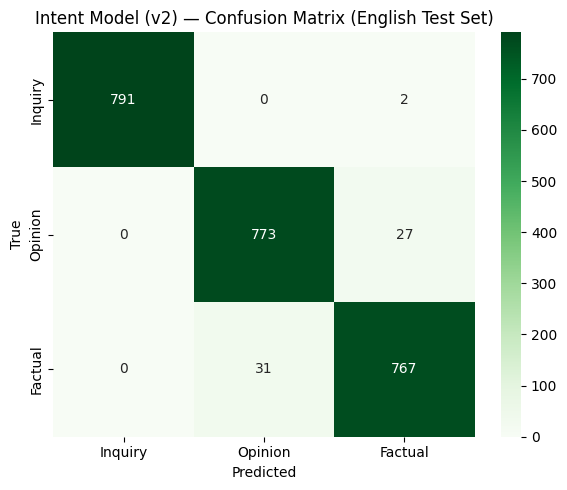

In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

predictions2 = intent_trainer2.predict(test_tokenized2)
pred_labels2 = np.argmax(predictions2.predictions, axis=1)
true_labels2 = test_tokenized2["label"]

cm2 = confusion_matrix(true_labels2, pred_labels2)
labels2 = ["Inquiry", "Opinion", "Factual"]

plt.figure(figsize=(6, 5))
sns.heatmap(cm2, annot=True, fmt="d", cmap="Greens", xticklabels=labels2, yticklabels=labels2)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Intent Model (v2) — Confusion Matrix (English Test Set)")
plt.tight_layout()
plt.savefig("/kaggle/working/intent_confusion_matrix.png", dpi=150)
plt.show()